In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, make_scorer

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)

In [5]:
import zipfile
import os

# Extract the zip file
zip_path = "/content/archive (4).zip"
if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall("/content/")
    print("Extracted files:", os.listdir("/content/"))

# Load the dataset
df = pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition.csv")
print("Dataset shape:", df.shape)
display(df.head())

Extracted files: ['.config', 'WA_Fn-UseC_-HR-Employee-Attrition.csv', 'archive (4).zip', 'sample_data']
Dataset shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


In [6]:
df.info()
display(df.isnull().sum().sort_values(ascending=False).to_frame("Missing values"))
display(df.describe(include="all").T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

,Missing values
Age,0
Attrition,0
BusinessTravel,0
DailyRate,0
Department,0
DistanceFromHome,0
Education,0
EducationField,0
EmployeeCount,0
EmployeeNumber,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,1470.0,NaN,NaN,NaN,36.92381,9.135373,18.0,30.0,36.0,43.0,60.0
Attrition,1470,2,No,1233,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BusinessTravel,1470,3,Travel_Rarely,1043,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DailyRate,1470.0,NaN,NaN,NaN,802.485714,403.5091,102.0,465.0,802.0,1157.0,1499.0
Department,1470,3,Research & Development,961,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DistanceFromHome,1470.0,NaN,NaN,NaN,9.192517,8.106864,1.0,2.0,7.0,14.0,29.0
Education,1470.0,NaN,NaN,NaN,2.912925,1.024165,1.0,2.0,3.0,4.0,5.0
EducationField,1470,6,Life Sciences,606,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EmployeeCount,1470.0,NaN,NaN,NaN,1.0,0.0,1.0,1.0,1.0,1.0,1.0
EmployeeNumber,1470.0,NaN,NaN,NaN,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0


Attrition
No     1233
Yes     237
Name: count, dtype: int64


,Percentage
Attrition,
No,83.88
Yes,16.12


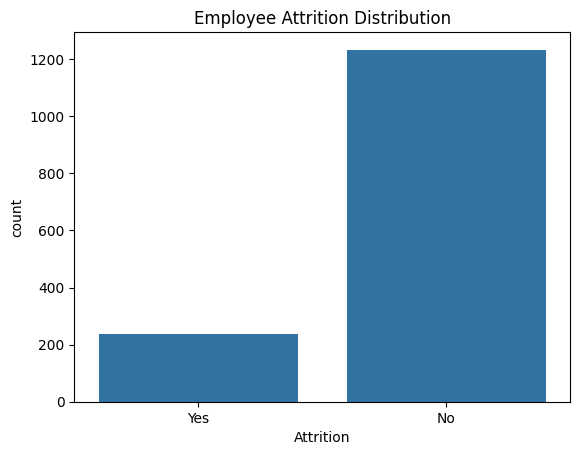

In [7]:
print(df["Attrition"].value_counts())
display((df["Attrition"].value_counts(normalize=True) * 100).round(2).to_frame("Percentage"))

sns.countplot(data=df, x="Attrition")
plt.title("Employee Attrition Distribution")
plt.show()

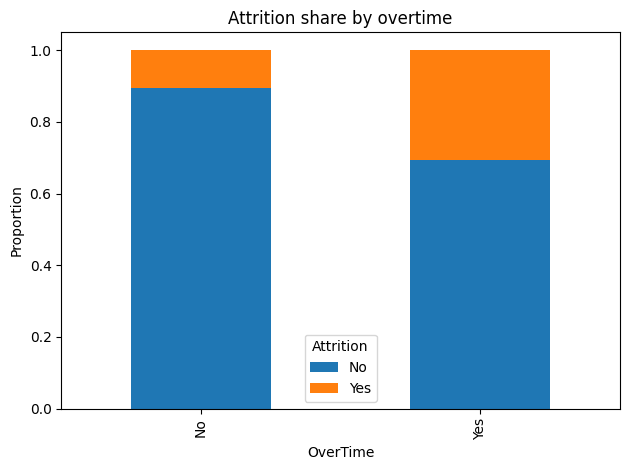

In [8]:
pd.crosstab(df["OverTime"], df["Attrition"], normalize="index").plot(kind="bar", stacked=True)
plt.title("Attrition share by overtime")
plt.ylabel("Proportion")
plt.tight_layout()
plt.show()

In [9]:
data = df.dropna(subset=["Attrition"]).copy()
X = data.drop(columns=["Attrition", "EmployeeNumber"], errors="ignore")
y = data["Attrition"].astype(str).str.strip()

constant_cols = [c for c in X.columns if X[c].nunique(dropna=True) <= 1]
X = X.drop(columns=constant_cols)

print("Feature shape:", X.shape)
display(y.value_counts())

Feature shape: (1470, 30)


,count
Attrition,
No,1233
Yes,237


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("X_train:", X_train.shape, "X_test:", X_test.shape)

X_train: (1176, 30) X_test: (294, 30)


In [11]:
numeric_features = X.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = [c for c in X.columns if c not in numeric_features]

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_features),
    ("cat", categorical_pipe, categorical_features)
])
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Numeric features: 23
Categorical features: 7


In [12]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Support Vector Classification": SVC(),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "AdaBoost": AdaBoostClassifier(random_state=RANDOM_STATE)
}

results, fitted_models, test_predictions = {}, {}, {}
for name, estimator in models.items():
    pipe = Pipeline([("preprocessor", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    fitted_models[name] = pipe
    test_predictions[name] = pred
    results[name] = {
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (Yes)": precision_score(y_test, pred, pos_label="Yes", zero_division=0),
        "Recall (Yes)": recall_score(y_test, pred, pos_label="Yes", zero_division=0),
        "F1-score (Yes)": f1_score(y_test, pred, pos_label="Yes", zero_division=0)
    }

results_df = pd.DataFrame(results).T.sort_values("F1-score (Yes)", ascending=False)
display(results_df.round(4))

,Accuracy,Precision (Yes),Recall (Yes),F1-score (Yes)
Logistic Regression,0.8605,0.6154,0.3404,0.4384
Decision Tree,0.7653,0.3103,0.3830,0.3429
AdaBoost,0.8299,0.4400,0.2340,0.3056
Support Vector Classification,0.8605,0.7500,0.1915,0.3051
Random Forest,0.8503,0.6364,0.1489,0.2414


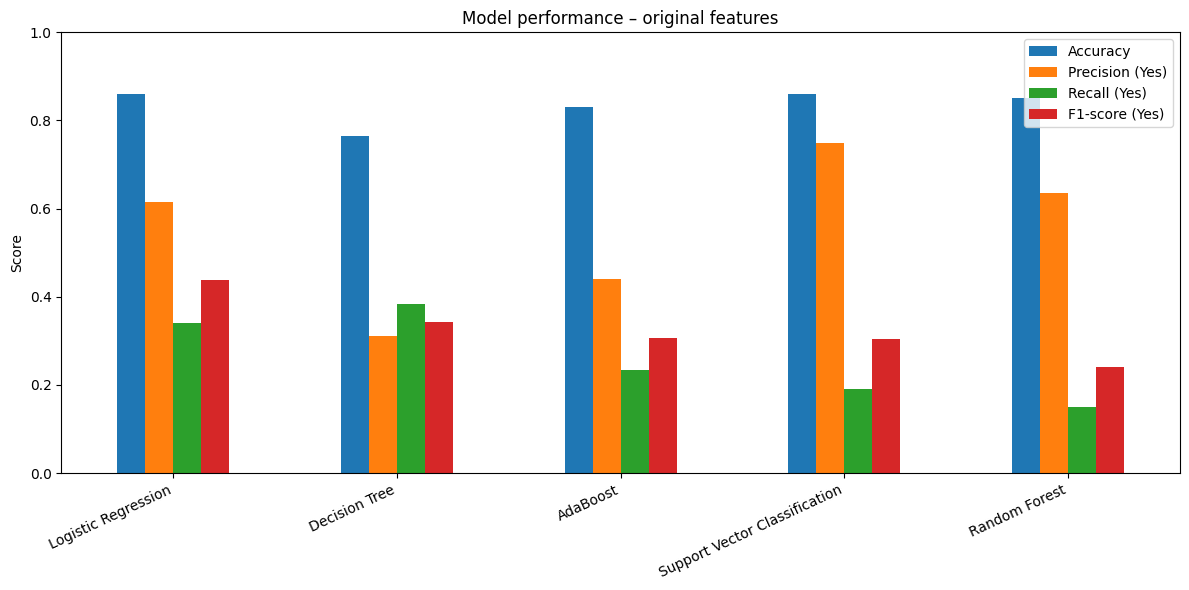

In [13]:
results_df.plot(kind="bar", figsize=(12, 6))
plt.title("Model performance – original features")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

Top model by test F1-score: Logistic Regression
              precision    recall  f1-score   support

          No       0.88      0.96      0.92       247
         Yes       0.62      0.34      0.44        47

    accuracy                           0.86       294
   macro avg       0.75      0.65      0.68       294
weighted avg       0.84      0.86      0.84       294



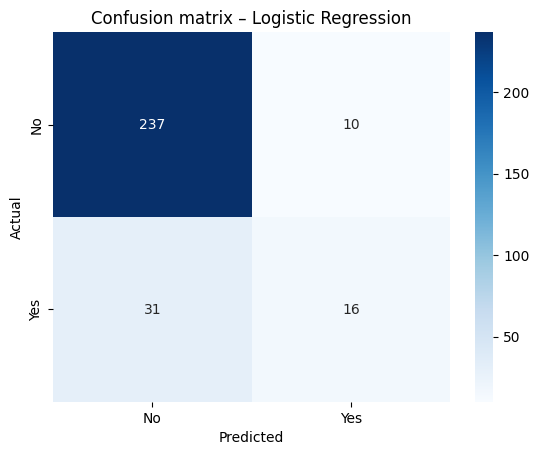

In [14]:
best_name = results_df.index[0]
best_pred = test_predictions[best_name]
print("Top model by test F1-score:", best_name)
print(classification_report(y_test, best_pred, zero_division=0))

labels = ["No", "Yes"]
cm = confusion_matrix(y_test, best_pred, labels=labels)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion matrix – " + best_name)
plt.show()

In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy",
    "precision_yes": make_scorer(precision_score, pos_label="Yes", zero_division=0),
    "recall_yes": make_scorer(recall_score, pos_label="Yes", zero_division=0),
    "f1_yes": make_scorer(f1_score, pos_label="Yes", zero_division=0)
}
cv_summary = {}
for name, estimator in models.items():
    pipe = Pipeline([("preprocessor", preprocessor), ("model", estimator)])
    scores = cross_validate(pipe, X, y, cv=cv, scoring=scoring)
    cv_summary[name] = {
        "CV Accuracy (mean)": scores["test_accuracy"].mean(),
        "CV Precision Yes (mean)": scores["test_precision_yes"].mean(),
        "CV Recall Yes (mean)": scores["test_recall_yes"].mean(),
        "CV F1 Yes (mean)": scores["test_f1_yes"].mean()
    }

cv_results_df = pd.DataFrame(cv_summary).T.sort_values("CV F1 Yes (mean)", ascending=False)
display(cv_results_df.round(4))

,CV Accuracy (mean),CV Precision Yes (mean),CV Recall Yes (mean),CV F1 Yes (mean)
Logistic Regression,0.8769,0.7053,0.4092,0.5171
AdaBoost,0.8735,0.7871,0.3039,0.4364
Decision Tree,0.7816,0.3531,0.3842,0.3655
Support Vector Classification,0.8667,0.8478,0.2152,0.3409
Random Forest,0.8571,0.7604,0.1814,0.2898


In [16]:
pca_results, pca_models, pca_predictions = {}, {}, {}
for name, estimator in models.items():
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("pca", PCA(n_components=0.95, svd_solver="full")),
        ("model", estimator)
    ])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    pca_models[name] = pipe
    pca_predictions[name] = pred
    pca_results[name] = {
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (Yes)": precision_score(y_test, pred, pos_label="Yes", zero_division=0),
        "Recall (Yes)": recall_score(y_test, pred, pos_label="Yes", zero_division=0),
        "F1-score (Yes)": f1_score(y_test, pred, pos_label="Yes", zero_division=0),
        "PCA components": pipe.named_steps["pca"].n_components_
    }

pca_results_df = pd.DataFrame(pca_results).T.sort_values("F1-score (Yes)", ascending=False)
display(pca_results_df.round(4))

,Accuracy,Precision (Yes),Recall (Yes),F1-score (Yes),PCA components
Logistic Regression,0.8844,0.7826,0.3830,0.5143,28.0
Support Vector Classification,0.8639,0.7692,0.2128,0.3333,28.0
AdaBoost,0.8367,0.4800,0.2553,0.3333,28.0
Decision Tree,0.7381,0.2500,0.3191,0.2804,28.0
Random Forest,0.8469,0.6667,0.0851,0.1509,28.0


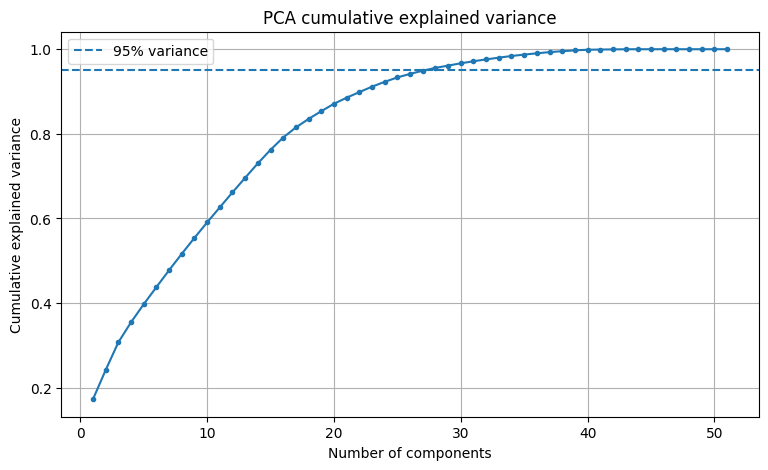

Components needed for 95% variance: 28
Preprocessed feature count: 51


In [17]:
X_train_processed = preprocessor.fit_transform(X_train)
pca_full = PCA(svd_solver="full")
pca_full.fit(X_train_processed)

cum_var = np.cumsum(pca_full.explained_variance_ratio_)
plt.figure(figsize=(9, 5))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker=".")
plt.axhline(0.95, linestyle="--", label="95% variance")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA cumulative explained variance")
plt.legend()
plt.grid(True)
plt.show()

n95 = np.argmax(cum_var >= 0.95) + 1
print("Components needed for 95% variance:", n95)
print("Preprocessed feature count:", X_train_processed.shape[1])

,Original features,PCA features
AdaBoost,0.3056,0.3333
Decision Tree,0.3429,0.2804
Logistic Regression,0.4384,0.5143
Random Forest,0.2414,0.1509
Support Vector Classification,0.3051,0.3333


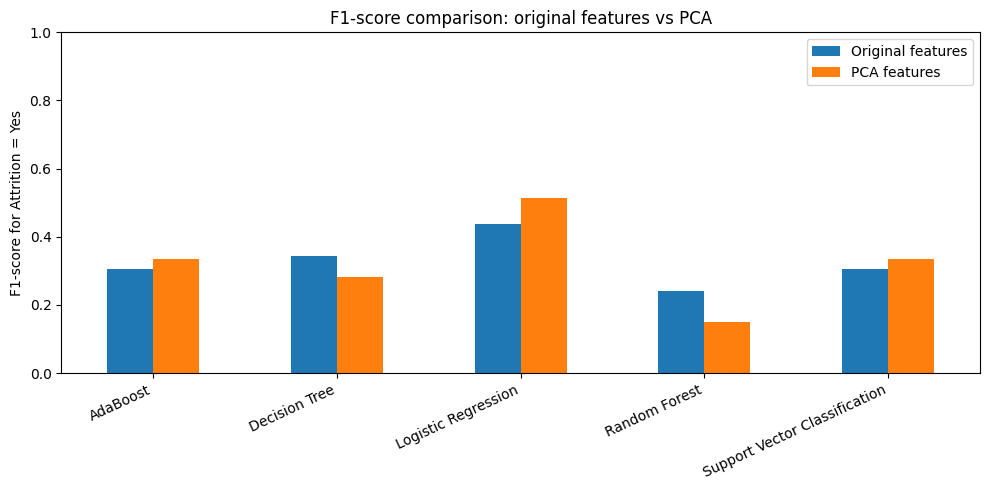

In [18]:
comparison = pd.DataFrame({
    "Original features": results_df["F1-score (Yes)"],
    "PCA features": pca_results_df["F1-score (Yes)"]
})
display(comparison.round(4))
comparison.plot(kind="bar", figsize=(10, 5))
plt.title("F1-score comparison: original features vs PCA")
plt.ylabel("F1-score for Attrition = Yes")
plt.ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()